### Build a Basic Chatbot

Components of LangGraph
1. Nodes: Individual functions or tasks that perform operations, such as calling an LLM or executing a tool.
2. Edges: Connections between nodes that define the workflow and determine which node executes next.
3. State: Shared data that stores and carries information between nodes throughout the graph execution.

In [2]:
from typing import Annotated 
# Annotated is used to attach additional information or metadata to a data type.
# In LangGraph, it is commonly used to define how state values should be updated.
from typing_extensions import TypedDict #TypedDict is used to define the structure of a dictionary
from langgraph.graph import StateGraph,START,END
# StateGraph
# - Used to create a graph-based workflow.
# - It manages nodes, edges, and shared state.
from langgraph.graph.message import add_messages
# add_messages is a message reducer.
# It controls how messages are updated in the graph's state.
# By default, it appends new messages to existing messages instead of replacing the entire list.
# It also handles message updates when messages have matching IDs.


In [3]:
# Define a class named State using TypedDict.
# TypedDict specifies the structure of the dictionary and the types of its values.
class State(TypedDict):

    
    # It appends new messages to existing messages instead of replacing the entire list.
    messages: Annotated[list, add_messages]
# My graph will maintain a state containing a messages field.




In [4]:
import os
from dotenv import load_dotenv
load_dotenv()


True

In [5]:
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain.chat_models import init_chat_model
llm=ChatGoogleGenerativeAI( model="gemini-3.5-flash")


In [6]:
## Node Functionality
def chatbot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}
# #But how does state get its value?

# LangGraph provides it automatically! When the graph executes this node, it passes the current state as the function argument.


In [7]:
graph_builder = StateGraph(State)
#Here, you're telling LangGraph to use the State structure for managing information throughout the workflow.
graph_builder.add_node("llmchatbot",chatbot)
graph_builder.add_edge(START,"llmchatbot")
graph_builder.add_edge("llmchatbot",END)


#compile the graph
graph=graph_builder.compile()




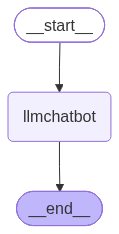

In [8]:
# Import Image to display image files or image data inside Jupyter Notebook.
from IPython.display import Image, display

# Use try to execute the code and catch any errors that may occur.
try:
    # Get the graph structure, convert it into a Mermaid PNG image,
    # and display that image inside the Jupyter Notebook.
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [9]:





# Purpose of Reducer:
# 1. Without add_messages
# Suppose your initial state contains:
# {    "messages": [        HumanMessage(content="hi")    ]}


# Your chatbot node returns:
# {    "messages": [        AIMessage(content="Hello! How can I help you today?")    ]}


# Without a reducer, LangGraph uses the default update behavior: the new value replaces the old value.

# Result:
# {    "messages": [        AIMessage(content="Hello! How can I help you today?")    ]}


# The original human message is lost from the state.
# 2. With add_messages
# When you define:
# messages: Annotated[list, add_messages]


# LangGraph uses add_messages to merge the new messages with the existing messages.

# Result:
# {    "messages": [        HumanMessage(content="hi"),        AIMessage(content="Hello! How can I help you today?")    ]}


# Now both messages are preserved!

### Chatbot with Tools

In [10]:
from langchain_tavily import TavilySearch
import os
from dotenv import load_dotenv

load_dotenv(override=True)
os.environ["TAVILY_API_KEY"] = os.getenv("TAVILY_API_KEY", "")
tool = TavilySearch(max_results=2)

# Execute a web search for the given query
response = tool.invoke("What is physics?")

# Display the search results
print(response)

{'query': 'What is physics?', 'follow_up_questions': None, 'answer': None, 'images': [], 'results': [{'url': 'https://www.unesco.org/en/query-list/p/physics', 'title': 'What are Physics? Meaning, Definition.', 'content': '# Physics\n\nPhysics is the branch of science that studies matter, energy, forces, and their interactions. It explores fundamental principles governing the universe, from subatomic particles to cosmic phenomena. Physics underlies technologies like electricity, mechanics, and quantum computing, shaping advancements in engineering, medicine, and space exploration through theoretical and experimental discoveries.', 'score': 0.88563144, 'raw_content': None, 'id': 'c70123-00'}, {'url': 'https://www.dictionary.com/browse/physics', 'title': 'PHYSICS Definition & Meaning | Dictionary.com', 'score': 0.8802834, 'content': '## noun\n\n1. the branch of science concerned with the properties of matter and energy and the relationships between them. It is based on mathematics and tra

In [11]:
def multiply(a:int,b:int)->int:
    """Multiply a and b"""
    


In [12]:
tools=[tool,multiply]
llm_with_tools=llm.bind_tools(tools)
llm_with_tools

_ChatModelBinding(bound=ChatGoogleGenerativeAI(metadata={'lc_versions': {'langchain-core': '1.8.4', 'langchain': '1.5.2', 'langchain-google-genai': '4.5.2'}}, profile={'name': 'Gemini 3.5 Flash', 'release_date': '2026-05-19', 'last_updated': '2026-05-19', 'open_weights': False, 'max_input_tokens': 1048576, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': True, 'pdf_inputs': True, 'video_inputs': True, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': True, 'image_url_inputs': True, 'image_tool_message': True, 'tool_choice': True, 'reasoning_effort_levels': ['minimal', 'low', 'medium', 'high'], 'reasoning_effort_default': 'medium'}, google_api_key=SecretStr('**********'), model='gemini-3.5-flash', temperature=None, client=<google.genai.client.Client object at 0x0000019774646C90>, default_metadata=(

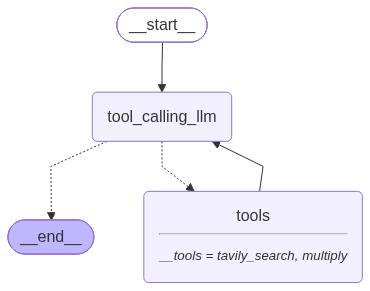

In [13]:
# Import StateGraph to create the LangGraph workflow
from langgraph.graph import StateGraph, START

# Import ToolNode to execute tools and tools_condition to decide whether to execute tools
from langgraph.prebuilt import ToolNode, tools_condition


# Define a node function that sends conversation messages to the LLM
def tool_calling_llm(state: State):

    # Invoke the LLM with the current conversation history
    # Return the LLM response as an update to the messages state
    return {"messages": [llm_with_tools.invoke(state["messages"])]}


# Create a graph builder using the previously defined State structure
builder = StateGraph(State)

# Register the LLM node
# First argument: node name
# Second argument: function that the node will execute
builder.add_node("tool_calling_llm", tool_calling_llm)

# Register the tools node
# ToolNode automatically executes the tools requested by the LLM
builder.add_node("tools", ToolNode(tools))


# Add edges

# Start the workflow from the LLM node
builder.add_edge(START, "tool_calling_llm")

# Decide whether to execute tools or finish the workflow
builder.add_conditional_edges(
    "tool_calling_llm",
    tools_condition
)

# After executing tools, send the result back to the LLM
builder.add_edge("tools", "tool_calling_llm")


# Compile the graph
graph = builder.compile()
display(Image(graph.get_graph().draw_mermaid_png()))

### Adding memory in an agent

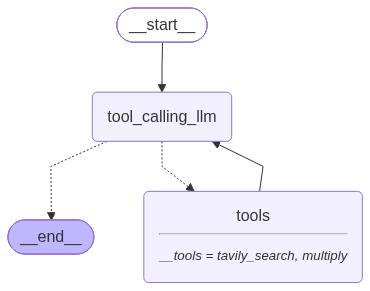

In [14]:
# Import StateGraph to create the LangGraph workflow
from langgraph.graph import StateGraph, START

# Import ToolNode to execute tools and tools_condition to decide whether to execute tools
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import MemorySaver
memory=MemorySaver()
# Define a node function that sends conversation messages to the LLM
def tool_calling_llm(state: State):

    # Invoke the LLM with the current conversation history
    # Return the LLM response as an update to the messages state
    return {"messages": [llm_with_tools.invoke(state["messages"])]}


# Create a graph builder using the previously defined State structure
builder = StateGraph(State)

# Register the LLM node
# First argument: node name
# Second argument: function that the node will execute
builder.add_node("tool_calling_llm", tool_calling_llm)

# Register the tools node
# ToolNode automatically executes the tools requested by the LLM
builder.add_node("tools", ToolNode(tools))


# Add edges

# Start the workflow from the LLM node
builder.add_edge(START, "tool_calling_llm")

# Decide whether to execute tools or finish the workflow
builder.add_conditional_edges(
    "tool_calling_llm",
    tools_condition
)

# After executing tools, send the result back to the LLM
builder.add_edge("tools", "tool_calling_llm")


# Compile the graph
graph = builder.compile(checkpointer=memory)
display(Image(graph.get_graph().draw_mermaid_png()))

In [15]:
config = {
    "configurable": {
        "thread_id": "1"
    }
}

response = graph.invoke(
    {"messages": [{"role": "user", "content": "My name is abhradip"}]},
    config=config
)

response

{'messages': [HumanMessage(content='My name is abhradip', additional_kwargs={}, response_metadata={}, id='ae6dbb8e-fcca-4bac-af97-35923f8736ba'),
  AIMessage(content=[{'type': 'text', 'text': 'Hello Abhradip! Nice to meet you. How can I help you today?', 'extras': {'signature': 'EuUCCuICAWkUfRMUVKeVdAwarV04G+hX9Y/d8ClXxVjLD6QBnSLrG7rwg4Dy1Avwo2qHFNpkIY8NCePI/bqP4stXkAWu2prDlWWprH4XU3LSfmkXB8omVHY0Oca3cDBzcIgekq5ROR6bH4q4qWiFxGEF3AuWVpHVGMDDKsKPkHbaxPH/8l+lVQZbYZxzYwATR8NjchRlmygkhCASRotpNj7ploJUCiBVImSp79SNCXu3ojsp79slMsosMPMvJgxyD8mkV7KUg4Y800SEZl+ygF1vlHRpeDVPn9tgQNo0zFHJiYdr17wT6xeDgKw/nLKrNmQelakgpg+C6YJoBC8OGbGACNyQ+ZyKmYeXTNk2MU/eGTs4Zm66mp8yFLtUPY05Z68uwWBGGT/yUbHu976m1ZCqfpH8FMLUjg67cjREnpqlQ5S4Ptx4y5USaelfYhL5V3PmKmaQIC4pPh95Wl+gcXSEX1FprnAS'}}], additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.6-flash', 'safety_ratings': [], 'normalized_finish_reason': 'stop', 'model_provider': 'google_genai'}, id='lc_run--01a20eb4-5239-73d4-bfd2-04309

In [16]:
config = {
    "configurable": {
        "thread_id": "1"
    }
}

response = graph.invoke(
    {"messages": [{"role": "user", "content": "hey do u remeber my name?"}]},
    config=config
)

response

{'messages': [HumanMessage(content='My name is abhradip', additional_kwargs={}, response_metadata={}, id='ae6dbb8e-fcca-4bac-af97-35923f8736ba'),
  AIMessage(content=[{'type': 'text', 'text': 'Hello Abhradip! Nice to meet you. How can I help you today?', 'extras': {'signature': 'EuUCCuICAWkUfRMUVKeVdAwarV04G+hX9Y/d8ClXxVjLD6QBnSLrG7rwg4Dy1Avwo2qHFNpkIY8NCePI/bqP4stXkAWu2prDlWWprH4XU3LSfmkXB8omVHY0Oca3cDBzcIgekq5ROR6bH4q4qWiFxGEF3AuWVpHVGMDDKsKPkHbaxPH/8l+lVQZbYZxzYwATR8NjchRlmygkhCASRotpNj7ploJUCiBVImSp79SNCXu3ojsp79slMsosMPMvJgxyD8mkV7KUg4Y800SEZl+ygF1vlHRpeDVPn9tgQNo0zFHJiYdr17wT6xeDgKw/nLKrNmQelakgpg+C6YJoBC8OGbGACNyQ+ZyKmYeXTNk2MU/eGTs4Zm66mp8yFLtUPY05Z68uwWBGGT/yUbHu976m1ZCqfpH8FMLUjg67cjREnpqlQ5S4Ptx4y5USaelfYhL5V3PmKmaQIC4pPh95Wl+gcXSEX1FprnAS'}}], additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.6-flash', 'safety_ratings': [], 'normalized_finish_reason': 'stop', 'model_provider': 'google_genai'}, id='lc_run--01a20eb4-5239-73d4-bfd2-04309